# Deep Learning – Module 4 Assignment
## Image Classification on Mini-ImageNet: CNN Design Study + Occlusion Sensitivity

**Part A (50 marks)** – Train CNNs on Mini-ImageNet and study how the following design choices affect classification performance:
1. number of convolutional layers
2. number of fully connected (FC) layers
3. number of filters per layer
4. max-pooling
5. training time (epochs)
6. stride

Then try to push the accuracy as high as possible and analyse mis-classified images.

**Part B (50 marks)** – Take the best model from Part A and run an **occlusion-sensitivity experiment** (Zeiler & Fergus, 2014, Figs. 7–8) on ~10 test images to check whether the model really looks at the object or relies on context.

---
### Notebook roadmap
| Step | Content |
|---|---|
| 0 | Setup (imports, seeds, GPU) |
| 1 | Data loading, splitting, GPU data pipeline |
| 2 | Configurable CNN (all Part-A knobs are constructor arguments) |
| 3 | Training / evaluation utilities |
| 4 | Part-A ablation study (one factor at a time) + results table |
| 5 | Improving the model (combine best settings, augmentation, regularisation) |
| 6 | Mis-classification analysis |
| 7 | Part-B occlusion sensitivity |
| 8 | Save artefacts (model, tables, figures) for the report |

> **Runtime:** use a GPU (`Runtime → Change runtime type → T4 GPU`). The full study takes roughly 1–1.5 h on a T4; reduce `BASE_TRAIN['epochs']` / `IMPROVED_EPOCHS` if you are short on time.

## Step 0 – Setup
Imports, reproducibility (fixed random seeds) and device selection.

In [2]:
import os, glob, time, copy, random, math, json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from tqdm.auto import tqdm
from IPython.display import display

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True
print("PyTorch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (training will be very slow!)")

OUT_DIR = "/content/outputs"          # tables / figures / model are saved here
os.makedirs(OUT_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

def savefig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=150, bbox_inches="tight")

PyTorch 2.11.0+cu130 | device: cuda | Tesla T4


## Step 1 – Data

### 1.1 Where is the dataset?
Download Mini-ImageNet from the link given in the assignment (100 classes × 600 images, 84×84 RGB) and place it in your Google Drive (or upload/unzip it to `/content`).
The loader below understands **three common layouts** automatically:

* `root/train|val|test/<class>/*.jpg`
* `root/<class>/*.jpg`
* a flat folder of images whose file names start with the class WordNet id (e.g. `n0153282900000005.jpg`, as produced by *mini-imagenet-tools*)

> 💡 Reading 60 000 small files straight from Google Drive is slow. Unzip the dataset to `/content/...` (e.g. `!unzip -q /content/drive/MyDrive/mini-imagenet.zip -d /content/mini-imagenet`) and point `DATA_DIR` there. After the first load, everything is cached into a single `.npz`, so later runs start in seconds.

> ⚠️ In the *few-shot* version of Mini-ImageNet the train/val/test folders contain **different classes**. For plain classification we need the **same classes** in all splits, so the code detects this situation and re-splits the pooled images in a stratified 80/10/10 manner.

In [5]:
# -------- EDIT THESE ------------------------------------------------------
USE_DRIVE = True
DATA_DIR  = "/content/drive/MyDrive/mini-imagenet/dataset"   # folder containing the dataset
IMG_SIZE  = 84                                       # images are resized to this size if needed
CACHE     = "/content/mini_imagenet_cache.npz"       # fast local cache
# --------------------------------------------------------------------------
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)
    print("Dataset folder:", DATA_DIR)
if not os.path.exists(DATA_DIR):
    !unzip -q /content/drive/MyDrive/dummy_mini_imagenet.zip -d /content/drive/MyDrive/mini-imagenet
print("Dataset folder exists:", os.path.isdir(DATA_DIR))

Mounted at /content/drive
Dataset folder: /content/drive/MyDrive/mini-imagenet/dataset
Dataset folder exists: True


In [6]:
IMG_EXT = (".jpg", ".jpeg", ".png")

def scan_dataset(root):
    """Return a DataFrame with columns: path, cls, split (split may be NaN)."""
    files = [p for p in glob.glob(os.path.join(root, "**", "*.*"), recursive=True) if p.lower().endswith(IMG_EXT)]
    recs = []
    for p in files:
        rel = os.path.relpath(p, root).split(os.sep)
        split = np.nan
        if rel[0].lower() in ("train", "val", "valid", "validation", "test"):
            split = {"valid": "val", "validation": "val"}.get(rel[0].lower(), rel[0].lower())
            rel = rel[1:]
        cls = rel[-2] if len(rel) >= 2 else os.path.basename(p)[:9]   # folder name, else WordNet-id prefix
        recs.append((p, cls, split))
    df = pd.DataFrame(recs, columns=["path", "cls", "split"])
    if df["cls"].nunique() < 20:        # e.g. one flat 'images/' folder -> class = WordNet-id prefix of the file name
        df["cls"] = [os.path.basename(p)[:9] for p in df["path"]]
    return df

def make_splits(df, test_frac=0.10, val_frac=0.10):
    df = df.copy()
    has_split = df["split"].notna().all()
    if has_split:                                   # are the classes shared between the splits?
        sets = df.groupby("split")["cls"].apply(set)
        if "train" not in sets.index or any(sets[s] != sets["train"] for s in sets.index):
            print("Split folders contain different classes -> pooling images and re-splitting (stratified).")
            has_split = False
    if not has_split:
        df["split"] = np.nan
        i_trva, i_te = train_test_split(df.index, test_size=test_frac, stratify=df["y"], random_state=SEED)
        i_tr, i_va = train_test_split(i_trva, test_size=val_frac / (1 - test_frac),
                                      stratify=df.loc[i_trva, "y"], random_state=SEED)
        df.loc[i_tr, "split"] = "train"; df.loc[i_va, "split"] = "val"; df.loc[i_te, "split"] = "test"
    elif "val" not in set(df["split"]):             # only train/test given -> carve a validation set from train
        i_tr_all = df.index[df["split"] == "train"]
        _, i_va = train_test_split(i_tr_all, test_size=val_frac, stratify=df.loc[i_tr_all, "y"], random_state=SEED)
        df.loc[i_va, "split"] = "val"
    return df

def load_image(p):
    im = Image.open(p).convert("RGB")
    if im.size != (IMG_SIZE, IMG_SIZE):
        im = im.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    return np.asarray(im, dtype=np.uint8)

if os.path.exists(CACHE):
    z = np.load(CACHE, allow_pickle=True)
    X_all, y_all, split_all, classes, paths_all = z["X"], z["y"], z["split"], list(z["classes"]), z["paths"]
    print("Loaded cached dataset:", X_all.shape)
else:
    df = scan_dataset(DATA_DIR)
    classes = sorted(df["cls"].unique())
    df["y"] = df["cls"].map({c: i for i, c in enumerate(classes)})
    df = make_splits(df)
    with ThreadPoolExecutor(16) as ex:
        X_all = np.stack(list(tqdm(ex.map(load_image, df["path"]), total=len(df), desc="Reading images")))
    y_all, split_all, paths_all = df["y"].values.astype(np.int64), df["split"].values.astype(str), df["path"].values.astype(str)
    np.savez(CACHE, X=X_all, y=y_all, split=split_all, classes=np.array(classes), paths=paths_all)
    print("Saved cache to", CACHE)

NUM_CLASSES = len(classes)
print(f"images: {X_all.shape} | classes: {NUM_CLASSES}")
print(pd.Series(split_all).value_counts().to_dict())

/tmp/ipykernel_440/2132630777.py:33: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'train' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[i_tr, "split"] = "train"; df.loc[i_va, "split"] = "val"; df.loc[i_te, "split"] = "test"


Reading images:   0%|          | 0/1200 [00:00<?, ?it/s]

Saved cache to /content/mini_imagenet_cache.npz
images: (1200, 84, 84, 3) | classes: 20
{'train': 959, 'val': 121, 'test': 120}


### 1.2 Move data to the GPU and compute normalisation statistics
The whole dataset (≈1.3 GB as `uint8`) fits in GPU memory. Keeping it there and doing augmentation **on the GPU** makes training much faster than a CPU `DataLoader` (important when we run many experiments).

Per-channel mean/std are computed on the **training split only**.

In [7]:
def split_tensors(name):
    m = split_all == name
    X = torch.from_numpy(X_all[m]).permute(0, 3, 1, 2).contiguous().to(device)   # uint8, N x 3 x H x W
    y = torch.from_numpy(y_all[m]).long().to(device)
    return X, y, paths_all[m]

Xtr, ytr, _          = split_tensors("train")
Xva, yva, _          = split_tensors("val")
Xte, yte, paths_te   = split_tensors("test")
print("train", tuple(Xtr.shape), "| val", tuple(Xva.shape), "| test", tuple(Xte.shape))

# channel statistics from the training split (computed in chunks to save memory)
s = torch.zeros(3, device=device, dtype=torch.float64); s2 = torch.zeros_like(s); cnt = 0
for i in range(0, len(Xtr), 4096):
    xb = Xtr[i:i + 4096].double() / 255
    s += xb.sum((0, 2, 3)); s2 += (xb ** 2).sum((0, 2, 3)); cnt += xb.shape[0] * xb.shape[2] * xb.shape[3]
MEAN = (s / cnt).float().view(1, 3, 1, 1)
STD  = (s2 / cnt - (s / cnt) ** 2).sqrt().float().view(1, 3, 1, 1)
print("mean", MEAN.flatten().tolist(), "std", STD.flatten().tolist())

def normalize(x01):   return (x01 - MEAN) / STD          # x in [0,1]
def to_numpy_img(u8): return u8.permute(1, 2, 0).cpu().numpy()   # 3xHxW uint8 -> HxWx3

del X_all   # free CPU RAM

train (959, 3, 84, 84) | val (121, 3, 84, 84) | test (120, 3, 84, 84)
mean [0.47346994280815125, 0.46447330713272095, 0.473450243473053] std [0.22051012516021729, 0.22543635964393616, 0.2275000512599945]


### 1.3 Readable class names + a quick look at the data
Class folders are WordNet ids (`n01532829`, …). If `nltk` + WordNet are available we convert them to readable names (falls back to the id otherwise).

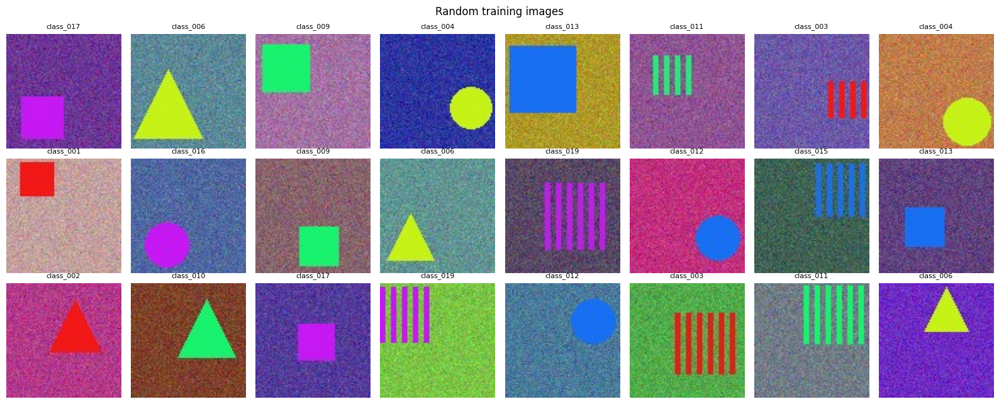

In [8]:
def wnid_to_name(w):
    try:
        from nltk.corpus import wordnet as wn
        return wn.synset_from_pos_and_offset("n", int(w[1:])).lemma_names()[0].replace("_", " ")
    except Exception:
        return w

try:
    import nltk; nltk.download("wordnet", quiet=True)
except Exception:
    pass
class_names = [wnid_to_name(c) if (len(c) == 9 and c[0] == "n" and c[1:].isdigit()) else c for c in classes]

fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for ax, i in zip(axes.flat, np.random.RandomState(0).choice(len(Xtr), 24, replace=False)):
    ax.imshow(to_numpy_img(Xtr[i])); ax.set_title(class_names[int(ytr[i])], fontsize=8); ax.axis("off")
plt.suptitle("Random training images"); plt.tight_layout(); savefig("fig_samples"); plt.show()

### 1.4 GPU data loader with augmentation
* `GPULoader` yields normalised mini-batches; the last incomplete batch is dropped for training (keeps BatchNorm happy).
* `augment_batch` = random horizontal flip + random translation (reflect-pad and random crop), done per-sample on the GPU.
* Augmentation is **off** in the ablation study (so that differences come from the studied factor only) and **on** when we try to maximise accuracy (Step 5).

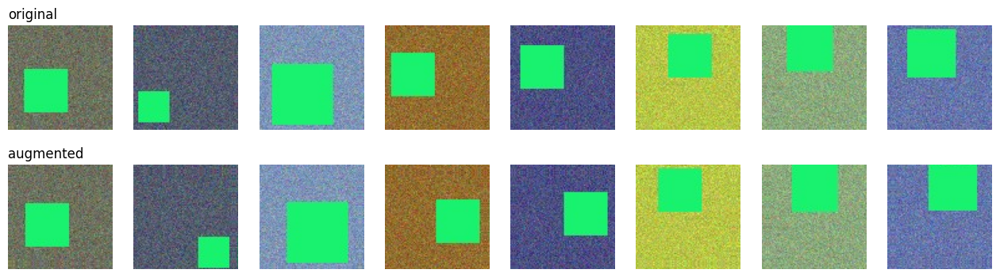

In [9]:
def augment_batch(x, pad=6):
    """x: B x 3 x H x W in [0,1]. Random h-flip + random translation via reflect-pad + crop."""
    B, C, H, W = x.shape
    flip = torch.rand(B, device=x.device) < 0.5
    x = torch.where(flip.view(B, 1, 1, 1), x.flip(3), x)
    xp = F.pad(x, (pad,) * 4, mode="reflect")
    i = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    j = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    rows = (i.view(B, 1) + torch.arange(H, device=x.device).view(1, H)).view(B, 1, H, 1)
    cols = (j.view(B, 1) + torch.arange(W, device=x.device).view(1, W)).view(B, 1, 1, W)
    bi = torch.arange(B, device=x.device).view(B, 1, 1, 1); ci = torch.arange(C, device=x.device).view(1, C, 1, 1)
    return xp[bi, ci, rows, cols]

class GPULoader:
    def __init__(self, X, y, batch_size=128, shuffle=False, augment=False, pad=6):
        self.X, self.y, self.bs, self.shuffle, self.augment, self.pad = X, y, batch_size, shuffle, augment, pad
        self.n = len(X)
    def __len__(self): return self.n // self.bs                  # drop last
    def __iter__(self):
        idx = torch.randperm(self.n, device=self.X.device) if self.shuffle else torch.arange(self.n, device=self.X.device)
        for k in range(len(self)):
            b = idx[k * self.bs:(k + 1) * self.bs]
            xb = self.X[b].float() / 255
            if self.augment: xb = augment_batch(xb, self.pad)
            yield normalize(xb), self.y[b]

# visual check of the augmentation
xb = Xtr[:8].float() / 255; xa = augment_batch(xb)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.2))
for k in range(8):
    axes[0, k].imshow(xb[k].permute(1, 2, 0).cpu()); axes[1, k].imshow(xa[k].permute(1, 2, 0).cpu())
    axes[0, k].axis("off"); axes[1, k].axis("off")
axes[0, 0].set_title("original", loc="left"); axes[1, 0].set_title("augmented", loc="left"); plt.show()

## Step 2 – A configurable CNN
One class covers every knob required in Part A:

| Argument | Meaning |
|---|---|
| `conv_channels` | list with the **number of filters** per conv stage → its length gives the **number of conv layers** |
| `convs_per_block` | conv layers per stage (VGG-style blocks; 1 in the ablation, 2 in the improved models) |
| `stride`, `stride_mode` | conv **stride** – on the first conv only (`'first'`) or on every conv (`'all'`) |
| `use_pool` | **Max-Pooling** (2×2) after every stage (skipped automatically when the feature map is already < 8 px) |
| `fc_sizes` | hidden sizes of the **FC layers** (`()` = a single linear classifier) |
| `dropout`, `use_bn` | regularisation / BatchNorm |

Each conv layer is `Conv(3×3, padding=1) → BatchNorm → ReLU`. Before the FC head the feature map is reduced to a fixed 4×4 grid with adaptive average pooling, so the FC input size does not explode for configurations without pooling or with small strides.

In [10]:
class ConfigurableCNN(nn.Module):
    def __init__(self, conv_channels=(32, 64, 128), convs_per_block=1, kernel_size=3, stride=1, stride_mode="first",
                 use_pool=True, fc_sizes=(256,), dropout=0.3, use_bn=True, num_classes=100,
                 in_size=IMG_SIZE, head_pool=4):
        super().__init__()
        layers, c_in, size, first = [], 3, in_size, True
        for c in conv_channels:
            for _ in range(convs_per_block):
                s = stride if (first or stride_mode == "all") else 1
                layers.append(nn.Conv2d(c_in, c, kernel_size, stride=s, padding=kernel_size // 2, bias=not use_bn))
                size = (size + 2 * (kernel_size // 2) - kernel_size) // s + 1
                if use_bn: layers.append(nn.BatchNorm2d(c))
                layers.append(nn.ReLU(inplace=True))
                c_in, first = c, False
            if use_pool and size >= 8:
                layers.append(nn.MaxPool2d(2)); size //= 2
        self.features = nn.Sequential(*layers)
        self.head_pool = nn.AdaptiveAvgPool2d(head_pool)
        d, fc = c_in * head_pool * head_pool, []
        for h in fc_sizes:
            fc += [nn.Linear(d, h), nn.ReLU(inplace=True), nn.Dropout(dropout)]; d = h
        fc.append(nn.Linear(d, num_classes))
        self.classifier = nn.Sequential(*fc)
        self.final_fmap = size
    def forward(self, x):
        return self.classifier(torch.flatten(self.head_pool(self.features(x)), 1))

def count_params(m): return sum(p.numel() for p in m.parameters()) / 1e6

# sanity check
m = ConfigurableCNN(num_classes=NUM_CLASSES).to(device)
print(m)
print(f"\nparams: {count_params(m):.2f} M | feature map before head: {m.final_fmap}x{m.final_fmap}")
print("output shape:", m(torch.randn(2, 3, IMG_SIZE, IMG_SIZE, device=device)).shape)
del m

ConfigurableCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head_pool): AdaptiveAvgPool2d(output_size=4)
  (classifier): Sequential(
    (0): L

## Step 3 – Training & evaluation utilities

* **Optimiser:** AdamW, cosine learning-rate decay (or constant LR for the epoch study), mixed precision (AMP) for speed.
* **Model selection:** the epoch with the best **validation** accuracy is kept; the reported **test** accuracy is measured with that checkpoint (the test set is never used for choosing anything).
* Test accuracy is *also logged every epoch* so that we can draw learning curves for the "training time" study.
* `run_experiment()` trains one configuration, appends a row to the global `RESULTS` list (this becomes the table of Part A), and remembers the best model overall.

In [11]:
@torch.no_grad()
def predict_logits(model, X, bs=512):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = normalize(X[i:i + bs].float() / 255).contiguous(memory_format=torch.channels_last)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            out.append(model(xb).float())
    return torch.cat(out)

def top_k_acc(logits, y, ks=(1, 5)):
    top = logits.topk(max(ks), dim=1).indices
    return [(top[:, :k] == y.view(-1, 1)).any(1).float().mean().item() for k in ks]

def train_model(cfg, epochs=15, lr=1e-3, weight_decay=5e-4, batch_size=128, augment=False,
                schedule="cosine", label_smoothing=0.0, verbose=True):
    seed_everything()
    model = ConfigurableCNN(**cfg).to(device).to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loader = GPULoader(Xtr, ytr, batch_size, shuffle=True, augment=augment)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(loader)) if schedule == "cosine" else None
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    crit = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    hist, best_val, best_state, best_ep, t0 = [], -1, None, 0, time.time()

    for ep in range(1, epochs + 1):
        model.train(); loss_sum = correct = n = 0
        for xb, yb in loader:
            xb = xb.contiguous(memory_format=torch.channels_last)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
                out = model(xb); loss = crit(out, yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if sched: sched.step()
            loss_sum += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
        va = top_k_acc(predict_logits(model, Xva), yva); te = top_k_acc(predict_logits(model, Xte), yte)
        hist.append(dict(epoch=ep, train_loss=loss_sum / n, train_acc=correct / n, val_acc=va[0], val_top5=va[1],
                         test_acc=te[0], test_top5=te[1]))
        if va[0] > best_val:
            best_val, best_ep = va[0], ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose and (ep % max(1, epochs // 10) == 0 or ep == epochs):
            print(f"  ep {ep:3d}/{epochs} | loss {loss_sum/n:.3f} | train {correct/n:.3f} | val {va[0]:.3f} | test {te[0]:.3f}")
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), dict(best_epoch=best_ep, train_time_s=time.time() - t0)

RESULTS = []                                     # one dict per experiment -> Part-A table
BEST = dict(val_acc=-1, cfg=None, state=None, name=None)

def run_experiment(group, name, overrides=None, **train_kw):
    cfg = {**BASE_CFG, **(overrides or {})}; tk = {**BASE_TRAIN, **train_kw}
    print(f"\n=== [{group}] {name} ===")
    model, hist, info = train_model(cfg, **tk)
    va = top_k_acc(predict_logits(model, Xva), yva); te = top_k_acc(predict_logits(model, Xte), yte)
    row = dict(group=group, name=name,
               conv_layers=len(cfg["conv_channels"]) * cfg["convs_per_block"], filters=str(list(cfg["conv_channels"])),
               fc_layers=len(cfg["fc_sizes"]) + 1, fc_sizes=str(list(cfg["fc_sizes"])),
               max_pool=cfg["use_pool"], stride=f'{cfg["stride"]} ({cfg["stride_mode"]})',
               epochs=tk["epochs"], augment=tk["augment"], params_M=round(count_params(model), 2),
               best_epoch=info["best_epoch"], train_time_s=round(info["train_time_s"]),
               val_acc=round(va[0] * 100, 2), test_acc=round(te[0] * 100, 2), test_top5=round(te[1] * 100, 2))
    RESULTS.append(row)
    print(f"  -> val {row['val_acc']:.2f}% | TEST top-1 {row['test_acc']:.2f}% | top-5 {row['test_top5']:.2f}% "
          f"| {row['params_M']} M params | {row['train_time_s']} s")
    if va[0] > BEST["val_acc"]:
        BEST.update(val_acc=va[0], cfg=cfg, name=f"{group}: {name}", test_acc=te[0],
                    state={k: v.cpu() for k, v in model.state_dict().items()})
    del model; torch.cuda.empty_cache()
    return hist, row

TABLE_COLS = ["name", "conv_layers", "filters", "fc_layers", "fc_sizes", "max_pool", "stride", "epochs",
              "params_M", "train_time_s", "val_acc", "test_acc", "test_top5"]
def show_group(g):
    d = pd.DataFrame(RESULTS); d = d[(d.group == g) | (d.group == "baseline")]
    display(d[TABLE_COLS].reset_index(drop=True))

## Step 4 – Part A: effect of each design parameter

**Protocol:** a *baseline* network is trained first; then **one factor at a time** is changed while everything else stays at the baseline value. All runs use the same seed, optimiser, schedule, 15 epochs and no data augmentation, so the numbers are comparable.

Baseline: 3 conv layers (32-64-128 filters, 3×3, stride 1) with max-pooling → 1 hidden FC layer (256) → output layer; BatchNorm + dropout 0.3.

In [12]:
BASE_CFG = dict(conv_channels=(32, 64, 128), convs_per_block=1, kernel_size=3, stride=1, stride_mode="first",
                use_pool=True, fc_sizes=(256,), dropout=0.3, use_bn=True, num_classes=NUM_CLASSES)
BASE_TRAIN = dict(epochs=15, lr=1e-3, weight_decay=5e-4, batch_size=128, augment=False,
                  schedule="cosine", label_smoothing=0.0)

_ = run_experiment("baseline", "baseline (3 conv, 2 FC, pool, stride 1)")


=== [baseline] baseline (3 conv, 2 FC, pool, stride 1) ===
  ep   1/15 | loss 2.818 | train 0.118 | val 0.174 | test 0.200
  ep   2/15 | loss 2.143 | train 0.298 | val 0.256 | test 0.275
  ep   3/15 | loss 1.764 | train 0.394 | val 0.281 | test 0.333
  ep   4/15 | loss 1.442 | train 0.489 | val 0.397 | test 0.475
  ep   5/15 | loss 1.217 | train 0.560 | val 0.496 | test 0.550
  ep   6/15 | loss 1.088 | train 0.580 | val 0.554 | test 0.617
  ep   7/15 | loss 0.978 | train 0.642 | val 0.595 | test 0.550
  ep   8/15 | loss 0.910 | train 0.627 | val 0.579 | test 0.575
  ep   9/15 | loss 0.880 | train 0.656 | val 0.603 | test 0.608
  ep  10/15 | loss 0.829 | train 0.669 | val 0.620 | test 0.617
  ep  11/15 | loss 0.783 | train 0.694 | val 0.636 | test 0.617
  ep  12/15 | loss 0.760 | train 0.708 | val 0.645 | test 0.617
  ep  13/15 | loss 0.724 | train 0.723 | val 0.612 | test 0.625
  ep  14/15 | loss 0.732 | train 0.715 | val 0.620 | test 0.617
  ep  15/15 | loss 0.703 | train 0.744 | val

### 4.1 Number of convolutional layers
1 → 5 conv layers (filters double each layer, capped at 256). The feature map is pooled after each layer until it reaches < 8 px.

In [13]:
for name, ov in [("1 conv",  dict(conv_channels=(32,))),
                 ("2 conv",  dict(conv_channels=(32, 64))),
                 ("4 conv",  dict(conv_channels=(32, 64, 128, 256))),
                 ("5 conv",  dict(conv_channels=(32, 64, 128, 256, 256)))]:
    run_experiment("conv_layers", name, ov)
show_group("conv_layers")


=== [conv_layers] 1 conv ===
  ep   1/15 | loss 2.939 | train 0.099 | val 0.157 | test 0.167
  ep   2/15 | loss 2.706 | train 0.171 | val 0.215 | test 0.233
  ep   3/15 | loss 2.516 | train 0.215 | val 0.231 | test 0.250
  ep   4/15 | loss 2.337 | train 0.247 | val 0.248 | test 0.258
  ep   5/15 | loss 2.159 | train 0.290 | val 0.248 | test 0.275
  ep   6/15 | loss 2.076 | train 0.321 | val 0.273 | test 0.308
  ep   7/15 | loss 1.950 | train 0.335 | val 0.306 | test 0.292
  ep   8/15 | loss 1.892 | train 0.343 | val 0.314 | test 0.300
  ep   9/15 | loss 1.890 | train 0.331 | val 0.306 | test 0.317
  ep  10/15 | loss 1.813 | train 0.359 | val 0.331 | test 0.317
  ep  11/15 | loss 1.802 | train 0.347 | val 0.306 | test 0.317
  ep  12/15 | loss 1.788 | train 0.371 | val 0.298 | test 0.325
  ep  13/15 | loss 1.770 | train 0.375 | val 0.298 | test 0.317
  ep  14/15 | loss 1.757 | train 0.413 | val 0.306 | test 0.308
  ep  15/15 | loss 1.777 | train 0.354 | val 0.306 | test 0.317
  -> val 3

,name,conv_layers,filters,fc_layers,fc_sizes,max_pool,stride,epochs,params_M,train_time_s,val_acc,test_acc,test_top5
0,"baseline (3 conv, 2 FC, pool, stride 1)",3,"[32, 64, 128]",2,[256],True,1 (first),15,0.62,3,64.46,61.67,95.83
1,1 conv,1,[32],2,[256],True,1 (first),15,0.14,1,33.06,31.67,92.50
2,2 conv,2,"[32, 64]",2,[256],True,1 (first),15,0.29,2,47.93,51.67,92.50
3,4 conv,4,"[32, 64, 128, 256]",2,[256],True,1 (first),15,1.44,2,67.77,67.50,99.17
4,5 conv,5,"[32, 64, 128, 256, 256]",2,[256],True,1 (first),15,2.03,2,70.25,69.17,99.17


### 4.2 Number of fully connected layers
Counted as *total* FC layers including the output layer (1 = a linear classifier directly on the conv features).

In [14]:
for name, ov in [("1 FC (output only)",      dict(fc_sizes=())),
                 ("3 FC (512-256-out)",       dict(fc_sizes=(512, 256))),
                 ("4 FC (512-256-128-out)",   dict(fc_sizes=(512, 256, 128))),
                 ("2 FC, wide (1024-out)",    dict(fc_sizes=(1024,)))]:
    run_experiment("fc_layers", name, ov)
show_group("fc_layers")


=== [fc_layers] 1 FC (output only) ===
  ep   1/15 | loss 2.700 | train 0.155 | val 0.256 | test 0.208
  ep   2/15 | loss 1.931 | train 0.375 | val 0.306 | test 0.367
  ep   3/15 | loss 1.483 | train 0.497 | val 0.355 | test 0.367
  ep   4/15 | loss 1.233 | train 0.587 | val 0.388 | test 0.458
  ep   5/15 | loss 1.060 | train 0.643 | val 0.479 | test 0.550
  ep   6/15 | loss 0.935 | train 0.692 | val 0.545 | test 0.567
  ep   7/15 | loss 0.831 | train 0.727 | val 0.570 | test 0.575
  ep   8/15 | loss 0.779 | train 0.750 | val 0.612 | test 0.617
  ep   9/15 | loss 0.715 | train 0.788 | val 0.620 | test 0.642
  ep  10/15 | loss 0.687 | train 0.789 | val 0.587 | test 0.608
  ep  11/15 | loss 0.661 | train 0.812 | val 0.645 | test 0.625
  ep  12/15 | loss 0.628 | train 0.823 | val 0.612 | test 0.608
  ep  13/15 | loss 0.616 | train 0.815 | val 0.612 | test 0.617
  ep  14/15 | loss 0.622 | train 0.812 | val 0.603 | test 0.617
  ep  15/15 | loss 0.603 | train 0.833 | val 0.603 | test 0.617


,name,conv_layers,filters,fc_layers,fc_sizes,max_pool,stride,epochs,params_M,train_time_s,val_acc,test_acc,test_top5
0,"baseline (3 conv, 2 FC, pool, stride 1)",3,"[32, 64, 128]",2,[256],True,1 (first),15,0.62,3,64.46,61.67,95.83
1,1 FC (output only),3,"[32, 64, 128]",1,[],True,1 (first),15,0.13,2,64.46,62.50,96.67
2,3 FC (512-256-out),3,"[32, 64, 128]",3,"[512, 256]",True,1 (first),15,1.28,2,61.16,53.33,97.50
3,4 FC (512-256-128-out),3,"[32, 64, 128]",4,"[512, 256, 128]",True,1 (first),15,1.31,2,54.55,55.00,97.50
4,"2 FC, wide (1024-out)",3,"[32, 64, 128]",2,[1024],True,1 (first),15,2.21,2,64.46,61.67,96.67


### 4.3 Number of filters per layer
Thinner/wider networks, plus constant-width and decreasing-width variants.

In [15]:
for name, ov in [("filters 16-32-64",    dict(conv_channels=(16, 32, 64))),
                 ("filters 64-128-256",  dict(conv_channels=(64, 128, 256))),
                 ("filters 128-256-512", dict(conv_channels=(128, 256, 512))),
                 ("filters 64-64-64 (constant)",  dict(conv_channels=(64, 64, 64))),
                 ("filters 128-64-32 (decreasing)", dict(conv_channels=(128, 64, 32)))]:
    run_experiment("filters", name, ov)
show_group("filters")


=== [filters] filters 16-32-64 ===
  ep   1/15 | loss 2.832 | train 0.115 | val 0.215 | test 0.167
  ep   2/15 | loss 2.338 | train 0.257 | val 0.281 | test 0.242
  ep   3/15 | loss 1.929 | train 0.343 | val 0.388 | test 0.292
  ep   4/15 | loss 1.684 | train 0.374 | val 0.413 | test 0.375
  ep   5/15 | loss 1.443 | train 0.490 | val 0.380 | test 0.442
  ep   6/15 | loss 1.278 | train 0.521 | val 0.455 | test 0.558
  ep   7/15 | loss 1.156 | train 0.557 | val 0.488 | test 0.517
  ep   8/15 | loss 1.111 | train 0.600 | val 0.512 | test 0.542
  ep   9/15 | loss 1.053 | train 0.590 | val 0.512 | test 0.567
  ep  10/15 | loss 0.958 | train 0.657 | val 0.562 | test 0.575
  ep  11/15 | loss 0.948 | train 0.641 | val 0.570 | test 0.625
  ep  12/15 | loss 0.937 | train 0.662 | val 0.570 | test 0.617
  ep  13/15 | loss 0.876 | train 0.704 | val 0.587 | test 0.608
  ep  14/15 | loss 0.880 | train 0.661 | val 0.587 | test 0.600
  ep  15/15 | loss 0.864 | train 0.667 | val 0.587 | test 0.600
  ->

,name,conv_layers,filters,fc_layers,fc_sizes,max_pool,stride,epochs,params_M,train_time_s,val_acc,test_acc,test_top5
0,"baseline (3 conv, 2 FC, pool, stride 1)",3,"[32, 64, 128]",2,[256],True,1 (first),15,0.62,3,64.46,61.67,95.83
1,filters 16-32-64,3,"[16, 32, 64]",2,[256],True,1 (first),15,0.29,3,58.68,60.83,97.50
2,filters 64-128-256,3,"[64, 128, 256]",2,[256],True,1 (first),15,1.43,4,65.29,56.67,97.50
3,filters 128-256-512,3,"[128, 256, 512]",2,[256],True,1 (first),15,3.58,10,58.68,53.33,96.67
4,filters 64-64-64 (constant),3,"[64, 64, 64]",2,[256],True,1 (first),15,0.34,3,64.46,60.83,96.67
5,filters 128-64-32 (decreasing),3,"[128, 64, 32]",2,[256],True,1 (first),15,0.23,4,61.16,64.17,99.17


### 4.4 Max-pooling
Baseline with and without the 2×2 max-pooling layers. Without pooling the feature maps stay at 84×84 so this run is noticeably slower.

In [16]:
run_experiment("pooling", "no max-pooling", dict(use_pool=False))
show_group("pooling")


=== [pooling] no max-pooling ===
  ep   1/15 | loss 2.745 | train 0.151 | val 0.240 | test 0.258
  ep   2/15 | loss 2.059 | train 0.314 | val 0.273 | test 0.325
  ep   3/15 | loss 1.743 | train 0.422 | val 0.322 | test 0.383
  ep   4/15 | loss 1.530 | train 0.446 | val 0.364 | test 0.433
  ep   5/15 | loss 1.387 | train 0.483 | val 0.471 | test 0.458
  ep   6/15 | loss 1.298 | train 0.529 | val 0.488 | test 0.550
  ep   7/15 | loss 1.177 | train 0.557 | val 0.479 | test 0.450
  ep   8/15 | loss 1.063 | train 0.625 | val 0.529 | test 0.517
  ep   9/15 | loss 1.018 | train 0.646 | val 0.554 | test 0.542
  ep  10/15 | loss 0.966 | train 0.652 | val 0.595 | test 0.533
  ep  11/15 | loss 0.907 | train 0.654 | val 0.570 | test 0.542
  ep  12/15 | loss 0.870 | train 0.698 | val 0.603 | test 0.525
  ep  13/15 | loss 0.849 | train 0.694 | val 0.603 | test 0.550
  ep  14/15 | loss 0.840 | train 0.700 | val 0.595 | test 0.542
  ep  15/15 | loss 0.813 | train 0.702 | val 0.595 | test 0.550
  -> v

,name,conv_layers,filters,fc_layers,fc_sizes,max_pool,stride,epochs,params_M,train_time_s,val_acc,test_acc,test_top5
0,"baseline (3 conv, 2 FC, pool, stride 1)",3,"[32, 64, 128]",2,[256],True,1 (first),15,0.62,3,64.46,61.67,95.83
1,no max-pooling,3,"[32, 64, 128]",2,[256],False,1 (first),15,0.62,8,60.33,52.50,94.17


### 4.5 Stride
Stride of the first conv layer (1 → 2 → 3) and an alternative where *all* conv layers use stride 2 and strided convolution replaces max-pooling.

In [17]:
for name, ov in [("stride 2 (first conv)", dict(stride=2)),
                 ("stride 3 (first conv)", dict(stride=3)),
                 ("stride 2 (all convs), no pool", dict(stride=2, stride_mode="all", use_pool=False))]:
    run_experiment("stride", name, ov)
show_group("stride")


=== [stride] stride 2 (first conv) ===
  ep   1/15 | loss 2.716 | train 0.125 | val 0.215 | test 0.275
  ep   2/15 | loss 1.998 | train 0.277 | val 0.207 | test 0.258
  ep   3/15 | loss 1.731 | train 0.360 | val 0.380 | test 0.350
  ep   4/15 | loss 1.465 | train 0.442 | val 0.438 | test 0.475
  ep   5/15 | loss 1.231 | train 0.532 | val 0.488 | test 0.458
  ep   6/15 | loss 1.094 | train 0.564 | val 0.545 | test 0.558
  ep   7/15 | loss 1.005 | train 0.598 | val 0.529 | test 0.550
  ep   8/15 | loss 0.933 | train 0.624 | val 0.595 | test 0.567
  ep   9/15 | loss 0.866 | train 0.641 | val 0.587 | test 0.567
  ep  10/15 | loss 0.820 | train 0.664 | val 0.620 | test 0.558
  ep  11/15 | loss 0.784 | train 0.672 | val 0.653 | test 0.600
  ep  12/15 | loss 0.744 | train 0.706 | val 0.636 | test 0.617
  ep  13/15 | loss 0.708 | train 0.719 | val 0.636 | test 0.608
  ep  14/15 | loss 0.705 | train 0.719 | val 0.661 | test 0.625
  ep  15/15 | loss 0.673 | train 0.756 | val 0.661 | test 0.617


,name,conv_layers,filters,fc_layers,fc_sizes,max_pool,stride,epochs,params_M,train_time_s,val_acc,test_acc,test_top5
0,"baseline (3 conv, 2 FC, pool, stride 1)",3,"[32, 64, 128]",2,[256],True,1 (first),15,0.62,3,64.46,61.67,95.83
1,stride 2 (first conv),3,"[32, 64, 128]",2,[256],True,2 (first),15,0.62,1,66.12,62.50,98.33
2,stride 3 (first conv),3,"[32, 64, 128]",2,[256],True,3 (first),15,0.62,1,65.29,58.33,98.33
3,"stride 2 (all convs), no pool",3,"[32, 64, 128]",2,[256],False,2 (all),15,0.62,1,58.68,57.50,95.83


### 4.6 Training time (number of epochs)
The baseline is trained for 30 epochs with a **constant** learning rate and metrics are logged every epoch, so accuracy after 5, 10, 15, 20, 25 and 30 epochs can be read off one run (with a cosine schedule the intermediate numbers would not be comparable). Train/val/test curves show the onset of over-fitting.


=== [epochs] 30 epochs, constant LR (final / best-val) ===
  ep   3/30 | loss 1.760 | train 0.394 | val 0.289 | test 0.342
  ep   6/30 | loss 1.063 | train 0.574 | val 0.579 | test 0.600
  ep   9/30 | loss 0.863 | train 0.661 | val 0.562 | test 0.617
  ep  12/30 | loss 0.670 | train 0.747 | val 0.587 | test 0.617
  ep  15/30 | loss 0.547 | train 0.780 | val 0.603 | test 0.650
  ep  18/30 | loss 0.434 | train 0.826 | val 0.702 | test 0.708
  ep  21/30 | loss 0.359 | train 0.867 | val 0.653 | test 0.758
  ep  24/30 | loss 0.289 | train 0.906 | val 0.711 | test 0.750
  ep  27/30 | loss 0.222 | train 0.939 | val 0.752 | test 0.833
  ep  30/30 | loss 0.152 | train 0.963 | val 0.785 | test 0.842
  -> val 78.51% | TEST top-1 86.67% | top-5 99.17% | 0.62 M params | 4 s


,name,conv_layers,filters,fc_layers,fc_sizes,max_pool,stride,epochs,params_M,train_time_s,val_acc,test_acc,test_top5
0,"baseline (3 conv, 2 FC, pool, stride 1)",3,"[32, 64, 128]",2,[256],True,1 (first),15,0.62,3.0,64.46,61.67,95.83
1,"30 epochs, constant LR (final / best-val)",3,"[32, 64, 128]",2,[256],True,1 (first),30,0.62,4.0,78.51,86.67,99.17
2,after 5 epochs (const LR),3,"[32, 64, 128]",2,[256],True,1 (first),5,0.62,NaN,54.55,51.67,92.50
3,after 10 epochs (const LR),3,"[32, 64, 128]",2,[256],True,1 (first),10,0.62,NaN,60.33,59.17,95.83
4,after 15 epochs (const LR),3,"[32, 64, 128]",2,[256],True,1 (first),15,0.62,NaN,60.33,65.00,97.50
5,after 20 epochs (const LR),3,"[32, 64, 128]",2,[256],True,1 (first),20,0.62,NaN,69.42,74.17,96.67
6,after 25 epochs (const LR),3,"[32, 64, 128]",2,[256],True,1 (first),25,0.62,NaN,71.07,79.17,97.50
7,after 30 epochs (const LR),3,"[32, 64, 128]",2,[256],True,1 (first),30,0.62,NaN,78.51,84.17,99.17


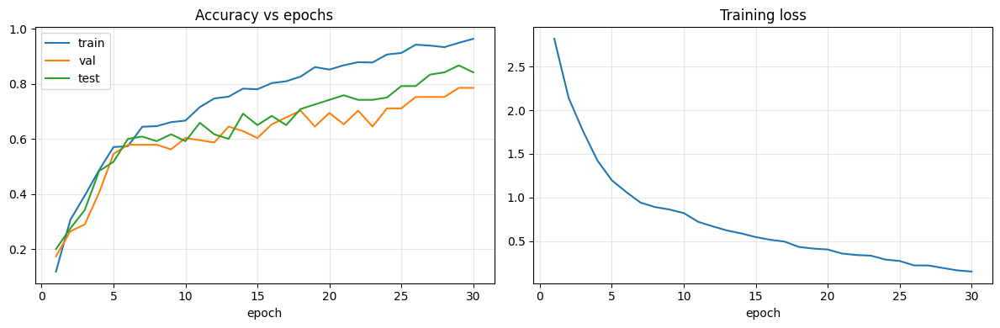

In [18]:
hist_ep, _ = run_experiment("epochs", "30 epochs, constant LR (final / best-val)", epochs=30, schedule="const")
for e in [5, 10, 15, 20, 25, 30]:
    h = hist_ep.iloc[e - 1]
    RESULTS.append(dict(group="epochs", name=f"after {e} epochs (const LR)", conv_layers=3, filters="[32, 64, 128]",
                        fc_layers=2, fc_sizes="[256]", max_pool=True, stride="1 (first)", epochs=e, augment=False,
                        params_M=RESULTS[0]["params_M"], best_epoch=e, train_time_s=np.nan,
                        val_acc=round(h.val_acc * 100, 2), test_acc=round(h.test_acc * 100, 2), test_top5=round(h.test_top5 * 100, 2)))
show_group("epochs")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist_ep.epoch, hist_ep.train_acc, label="train"); ax[0].plot(hist_ep.epoch, hist_ep.val_acc, label="val")
ax[0].plot(hist_ep.epoch, hist_ep.test_acc, label="test"); ax[0].set_title("Accuracy vs epochs"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(hist_ep.epoch, hist_ep.train_loss); ax[1].set_title("Training loss"); ax[1].set_xlabel("epoch"); ax[1].grid(alpha=.3)
plt.tight_layout(); savefig("fig_epochs_curve"); plt.show()

### 4.7 Summary table and plots of the study
The table below is the main deliverable of Part A (`partA_results_table.csv`). The bar charts show test accuracy for each factor (the baseline is included in each panel).

,group,name,conv_layers,filters,fc_layers,fc_sizes,max_pool,stride,epochs,params_M,train_time_s,val_acc,test_acc,test_top5
0,baseline,"baseline (3 conv, 2 FC, pool, stride 1)",3,"[32, 64, 128]",2,[256],True,1 (first),15,0.62,3.00,64.46,61.67,95.83
1,conv_layers,1 conv,1,[32],2,[256],True,1 (first),15,0.14,1.00,33.06,31.67,92.50
2,conv_layers,2 conv,2,"[32, 64]",2,[256],True,1 (first),15,0.29,2.00,47.93,51.67,92.50
3,conv_layers,4 conv,4,"[32, 64, 128, 256]",2,[256],True,1 (first),15,1.44,2.00,67.77,67.50,99.17
4,conv_layers,5 conv,5,"[32, 64, 128, 256, 256]",2,[256],True,1 (first),15,2.03,2.00,70.25,69.17,99.17
5,fc_layers,1 FC (output only),3,"[32, 64, 128]",1,[],True,1 (first),15,0.13,2.00,64.46,62.50,96.67
6,fc_layers,3 FC (512-256-out),3,"[32, 64, 128]",3,"[512, 256]",True,1 (first),15,1.28,2.00,61.16,53.33,97.50
7,fc_layers,4 FC (512-256-128-out),3,"[32, 64, 128]",4,"[512, 256, 128]",True,1 (first),15,1.31,2.00,54.55,55.00,97.50
8,fc_layers,"2 FC, wide (1024-out)",3,"[32, 64, 128]",2,[1024],True,1 (first),15,2.21,2.00,64.46,61.67,96.67
9,filters,filters 16-32-64,3,"[16, 32, 64]",2,[256],True,1 (first),15,0.29,3.00,58.68,60.83,97.50


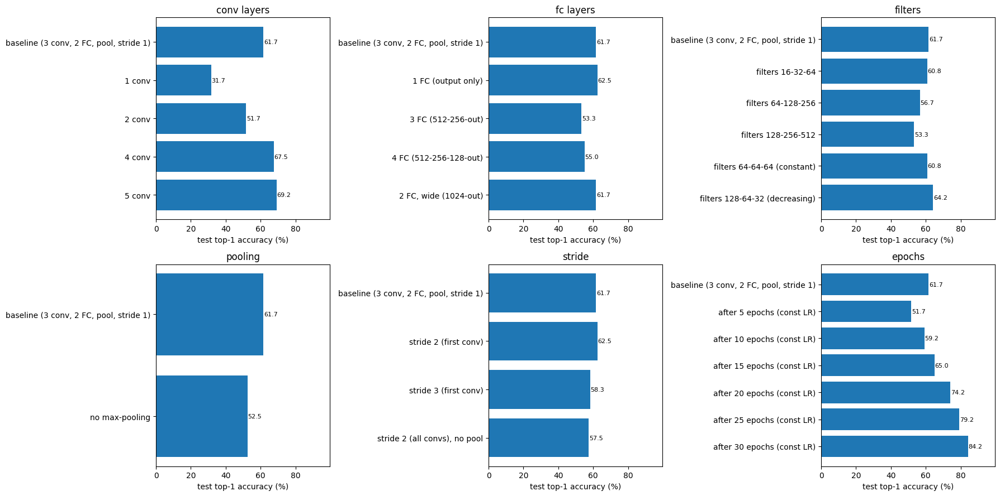

In [19]:
res = pd.DataFrame(RESULTS)
res.to_csv(f"{OUT_DIR}/partA_results_table_all_runs.csv", index=False)
display(res[["group"] + TABLE_COLS].style.format(precision=2).background_gradient(subset=["test_acc"], cmap="YlGn"))

groups = ["conv_layers", "fc_layers", "filters", "pooling", "stride", "epochs"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, g in zip(axes.flat, groups):
    d = res[(res.group == g) | (res.group == "baseline")]
    d = d[~d.name.str.contains("30 epochs, constant")] if g == "epochs" else d
    ax.barh(d.name, d.test_acc, color="tab:blue"); ax.invert_yaxis()
    for y_, v in enumerate(d.test_acc): ax.text(v + 0.2, y_, f"{v:.1f}", va="center", fontsize=8)
    ax.set_title(g.replace("_", " ")); ax.set_xlabel("test top-1 accuracy (%)"); ax.set_xlim(0, max(res.test_acc) * 1.15)
plt.tight_layout(); savefig("fig_partA_ablation_bars"); plt.show()

## Step 5 – Improving the performance
Now we combine what the ablation study suggests (see the table above) and add standard ingredients that help most on small-data problems:

* **Deeper VGG-style stages** (2 conv layers per stage → 6 or 8 conv layers) with BatchNorm
* **Wider filters** (64-128-256(-512))
* **Data augmentation** (random flip + random translation)
* **Stronger regularisation:** dropout 0.5, weight decay, label smoothing 0.1
* **Longer training** with cosine learning-rate decay

> ✏️ After looking at your own results in Step 4.7 you may want to edit the candidate list below (e.g. if a different width, stride or FC depth turned out best). Reduce `IMPROVED_EPOCHS` if runtime is a problem.

In [20]:
IMPROVED_EPOCHS = 40
IMPROVED_TRAIN = dict(epochs=IMPROVED_EPOCHS, lr=2e-3, weight_decay=5e-4, batch_size=128,
                      augment=True, schedule="cosine", label_smoothing=0.1)

candidates = [
    ("A: 4 conv (64-128-256-512) + aug",         dict(conv_channels=(64, 128, 256, 512), fc_sizes=(512,), dropout=0.5)),
    ("B: VGG-style 6 conv (64-128-256 x2) + aug", dict(conv_channels=(64, 128, 256), convs_per_block=2, fc_sizes=(512,), dropout=0.5)),
    ("C: VGG-style 8 conv (64-128-256-512 x2) + aug", dict(conv_channels=(64, 128, 256, 512), convs_per_block=2, fc_sizes=(512,), dropout=0.5)),
]
hist_improved = {}
for name, ov in candidates:
    hist_improved[name], _ = run_experiment("improved", name, ov, **IMPROVED_TRAIN)
show_group("improved")


=== [improved] A: 4 conv (64-128-256-512) + aug ===
  ep   4/40 | loss 2.534 | train 0.172 | val 0.165 | test 0.175
  ep   8/40 | loss 2.042 | train 0.308 | val 0.355 | test 0.392
  ep  12/40 | loss 1.856 | train 0.395 | val 0.496 | test 0.467
  ep  16/40 | loss 1.707 | train 0.463 | val 0.455 | test 0.492
  ep  20/40 | loss 1.613 | train 0.506 | val 0.595 | test 0.542
  ep  24/40 | loss 1.533 | train 0.550 | val 0.570 | test 0.592
  ep  28/40 | loss 1.484 | train 0.578 | val 0.628 | test 0.600
  ep  32/40 | loss 1.442 | train 0.603 | val 0.628 | test 0.592
  ep  36/40 | loss 1.431 | train 0.617 | val 0.653 | test 0.617
  ep  40/40 | loss 1.412 | train 0.614 | val 0.645 | test 0.625
  -> val 66.12% | TEST top-1 59.17% | top-5 100.00% | 5.76 M params | 13 s

=== [improved] B: VGG-style 6 conv (64-128-256 x2) + aug ===
  ep   4/40 | loss 2.051 | train 0.326 | val 0.223 | test 0.208
  ep   8/40 | loss 1.724 | train 0.462 | val 0.380 | test 0.292
  ep  12/40 | loss 1.537 | train 0.568 | v

,name,conv_layers,filters,fc_layers,fc_sizes,max_pool,stride,epochs,params_M,train_time_s,val_acc,test_acc,test_top5
0,"baseline (3 conv, 2 FC, pool, stride 1)",3,"[32, 64, 128]",2,[256],True,1 (first),15,0.62,3.0,64.46,61.67,95.83
1,A: 4 conv (64-128-256-512) + aug,4,"[64, 128, 256, 512]",2,[512],True,1 (first),40,5.76,13.0,66.12,59.17,100.00
2,B: VGG-style 6 conv (64-128-256 x2) + aug,6,"[64, 128, 256]",2,[512],True,1 (first),40,3.25,23.0,68.60,73.33,100.00
3,C: VGG-style 8 conv (64-128-256-512 x2) + aug,8,"[64, 128, 256, 512]",2,[512],True,1 (first),40,8.89,27.0,71.07,70.83,100.00


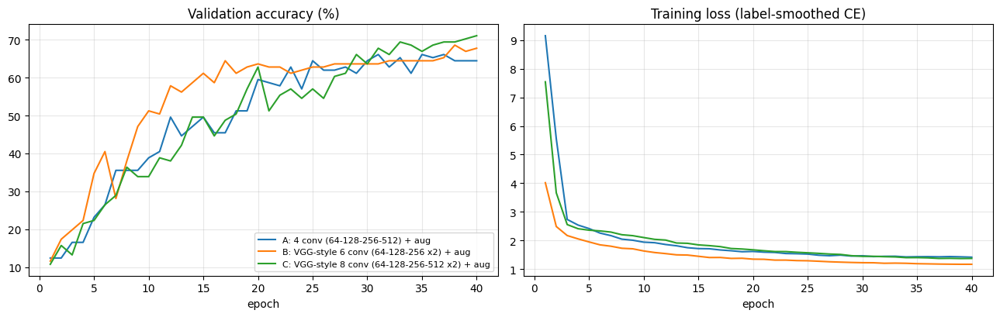

BEST MODEL: epochs: 30 epochs, constant LR (final / best-val)
params 0.62 M | validation acc 78.51% | TEST top-1 86.67% | top-5 99.17%


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for name, h in hist_improved.items():
    ax[0].plot(h.epoch, h.val_acc * 100, label=name); ax[1].plot(h.epoch, h.train_loss, label=name)
ax[0].set_title("Validation accuracy (%)"); ax[1].set_title("Training loss (label-smoothed CE)")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
ax[0].legend(fontsize=8); plt.tight_layout(); savefig("fig_improved_curves"); plt.show()

# ---- rebuild the BEST model (selected by validation accuracy over ALL runs) ----
best_model = ConfigurableCNN(**BEST["cfg"]).to(device).to(memory_format=torch.channels_last)
best_model.load_state_dict({k: v.to(device) for k, v in BEST["state"].items()}); best_model.eval()
lg = predict_logits(best_model, Xte); t1, t5 = top_k_acc(lg, yte)
print("BEST MODEL:", BEST["name"])
print(f"params {count_params(best_model):.2f} M | validation acc {BEST['val_acc']*100:.2f}% | TEST top-1 {t1*100:.2f}% | top-5 {t5*100:.2f}%")

## Step 6 – Analysis of mis-classified images
Using the best model we look at
1. overall and **per-class accuracy** (which classes are easy / hard),
2. the **most confused class pairs** (from the confusion matrix),
3. **images that were mis-classified** – random ones and the most *confidently* wrong ones,
4. example training images of the true and predicted class of the top confused pairs, to judge whether the confusion is visually plausible.

Test accuracy: 86.67%   (errors: 16 / 120)
Of the errors, the true class is still within the top-5 predictions for 93.8%
Mean confidence on correct predictions: 0.852 | on wrong predictions: 0.715


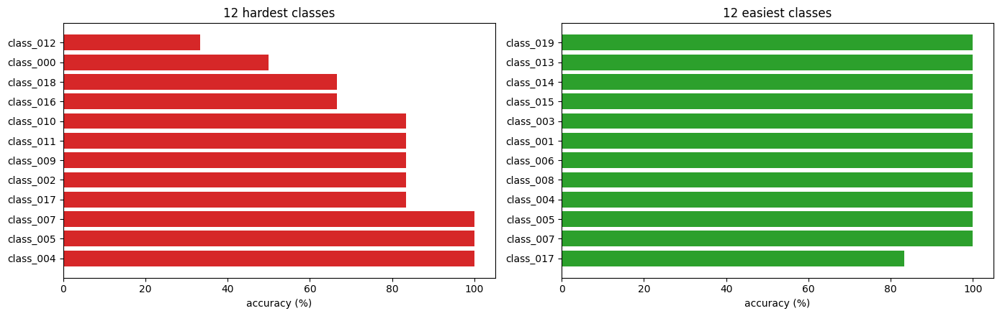

,true class,predicted as,# images
0,class_000,class_001,2
1,class_012,class_013,2
2,class_018,class_016,2
3,class_016,class_017,2
4,class_002,class_013,1
5,class_000,class_002,1
6,class_011,class_009,1
7,class_010,class_008,1
8,class_009,class_008,1
9,class_012,class_014,1


In [22]:
probs_te = F.softmax(predict_logits(best_model, Xte), 1)
conf_te, pred_te = probs_te.max(1)
wrong_mask = pred_te != yte
y_np, p_np = yte.cpu().numpy(), pred_te.cpu().numpy()
top5_hit = (probs_te.topk(5, 1).indices == yte.view(-1, 1)).any(1)

print(f"Test accuracy: {(~wrong_mask).float().mean()*100:.2f}%   (errors: {int(wrong_mask.sum())} / {len(yte)})")
print(f"Of the errors, the true class is still within the top-5 predictions for {top5_hit[wrong_mask].float().mean()*100:.1f}%")
print(f"Mean confidence on correct predictions: {conf_te[~wrong_mask].mean():.3f} | on wrong predictions: {conf_te[wrong_mask].mean():.3f}")

# ---- per-class accuracy ----
cm = confusion_matrix(y_np, p_np, labels=range(NUM_CLASSES))
per_class = cm.diagonal() / cm.sum(1).clip(min=1)
order = np.argsort(per_class)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, idx, title, col in [(ax[0], order[:12], "12 hardest classes", "tab:red"), (ax[1], order[::-1][:12], "12 easiest classes", "tab:green")]:
    a.barh([class_names[i] for i in idx], per_class[idx] * 100, color=col); a.invert_yaxis(); a.set_title(title); a.set_xlabel("accuracy (%)")
plt.tight_layout(); savefig("fig_per_class_accuracy"); plt.show()

# ---- most confused pairs ----
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = [(i, j, off[i, j]) for i, j in zip(*np.unravel_index(np.argsort(off, axis=None)[::-1][:15], off.shape))]
conf_pairs = pd.DataFrame([(class_names[i], class_names[j], n) for i, j, n in pairs], columns=["true class", "predicted as", "# images"])
display(conf_pairs)
conf_pairs.to_csv(f"{OUT_DIR}/partA_top_confusions.csv", index=False)

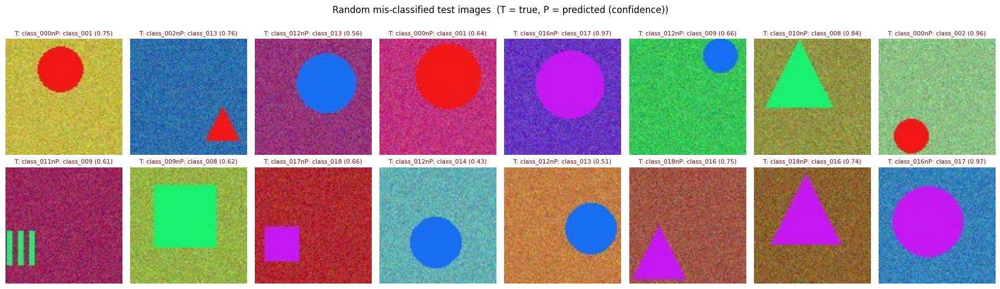

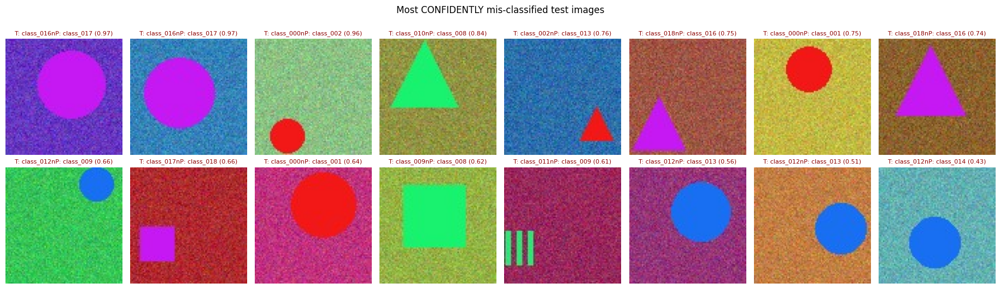

In [24]:
def show_images(idx_list, title, ncols=8, fname=None):
    if len(idx_list) == 0:
        print(f"No images to display for: {title}")
        return
    nrows = math.ceil(len(idx_list) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.3 * ncols, 2.7 * nrows))
    for ax in np.atleast_1d(axes).flat: ax.axis("off")
    for ax, i in zip(np.atleast_1d(axes).flat, idx_list):
        ax.imshow(to_numpy_img(Xte[i]))
        ax.set_title(f"T: {class_names[int(yte[i])]}nP: {class_names[int(pred_te[i])]} ({conf_te[i]:.2f})", fontsize=8, color="darkred")
    plt.suptitle(title, y=1.0); plt.tight_layout()
    if fname: savefig(fname)
    plt.show()

wrong_idx = wrong_mask.nonzero().flatten().cpu().numpy()
rng = np.random.RandomState(1)
# Use min(24, len(wrong_idx)) to avoid sampling more elements than available
num_to_sample = min(24, len(wrong_idx))
sampled_wrong_idx = rng.choice(wrong_idx, num_to_sample, replace=False)
show_images(sampled_wrong_idx, "Random mis-classified test images  (T = true, P = predicted (confidence))", fname="fig_misclassified_random")

# most confident mistakes
conf_wrong = conf_te.cpu().numpy()[wrong_idx]
show_images(wrong_idx[np.argsort(-conf_wrong)[:16]], "Most CONFIDENTLY mis-classified test images", fname="fig_misclassified_confident")

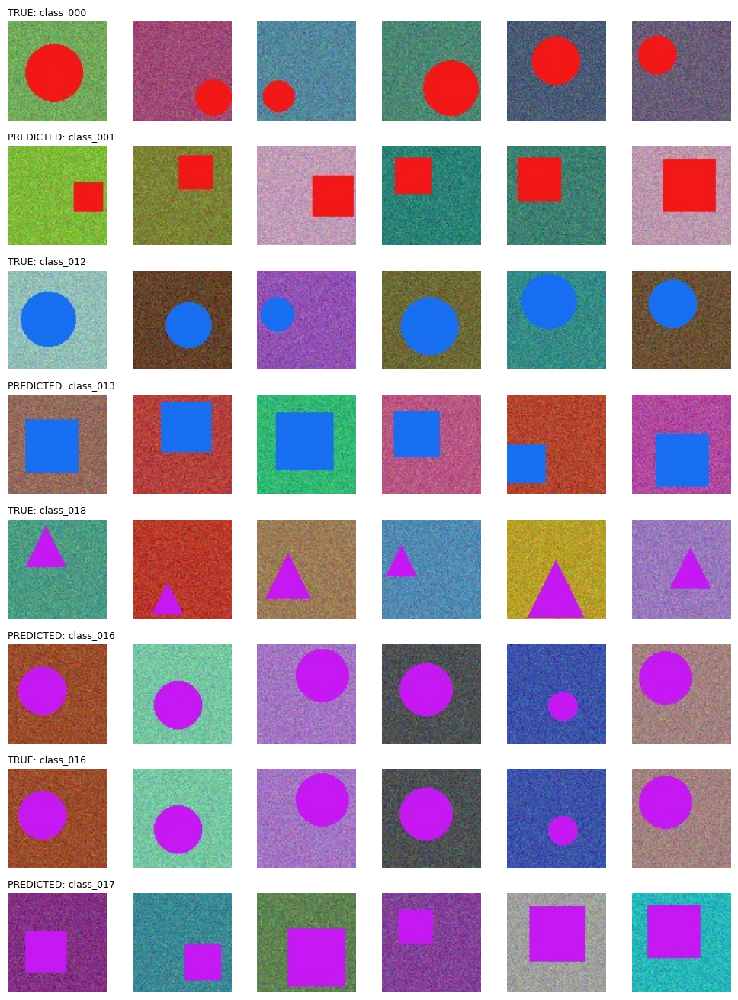

In [25]:
# Do the true class and the predicted class of the top confused pairs look alike?  (show 6 training images of each)
def class_examples(c, k=6):
    idx = (ytr == c).nonzero().flatten()[:k].cpu().numpy()
    return [to_numpy_img(Xtr[i]) for i in idx]

top_pairs = [(i, j) for i, j, n in pairs[:4]]
fig, axes = plt.subplots(len(top_pairs) * 2, 6, figsize=(10, 3.3 * len(top_pairs)))
for r, (i, j) in enumerate(top_pairs):
    for row_off, c, tag in [(0, i, "TRUE"), (1, j, "PREDICTED")]:
        for k, im in enumerate(class_examples(c)):
            ax = axes[2 * r + row_off, k]; ax.imshow(im); ax.axis("off")
            if k == 0: ax.set_title(f"{tag}: {class_names[c]}", fontsize=9, loc="left")
plt.tight_layout(); savefig("fig_confused_pairs_examples"); plt.show()

**What to look for when writing the discussion** (fill in using the figures above):
* **Fine-grained / visually similar classes** (e.g. different dog breeds, similar vehicles, similar animals) → confusions concentrated in a few class pairs.
* **Multiple objects in the frame** – the image contains the predicted class too (ImageNet labels one object per image although several may be present).
* **Small, partially visible or off-centre objects**, clutter, unusual viewpoint or lighting.
* **Contextual / background cues** – e.g. water → boats, grass → animals (this links directly to Part B).
* **Low resolution** (84×84) removing the discriminative texture/detail.
* Confident mistakes may indicate label noise or genuinely ambiguous images; the fact that most errors still have the true class in the top-5 shows the confusions are "reasonable".

## Step 7 – Part B: Occlusion sensitivity
**Question:** has the best model learnt *where the object is*, or does it classify mostly from surrounding / contextual cues?

**Procedure** (Zeiler & Fergus 2014, Figs. 7–8). For every pixel position *(i, j)* (i = x, j = y):
1. replace an **N × N window centred at (i, j)** by **gray** pixels (value 0.5; the window is clipped at the image border),
2. pass the modified image through the model,
3. store the **probability of the true class** → `confidence(i, j)`,
4. plot the array as an image. A strong drop in confidence when a region is hidden means the model *depends on that region*.

Implementation notes: all occluded copies of one image are built on the GPU and evaluated in large batches (84×84 = 7 056 forward passes per image at stride 1 – only seconds). Window size `N` must be odd; `N = 11` (≈ 13 % of the image width) is the default and a window-size study follows.

In [26]:
@torch.no_grad()
def occlusion_map(model, img_u8, true_cls, N=11, stride=1, gray=0.5, batch_size=1024):
    """Returns (conf_map, pred_map, base_conf). Maps have shape (H/stride, W/stride); row = y (j), col = x (i)."""
    assert N % 2 == 1, "N must be odd"
    model.eval()
    _, H, W = img_u8.shape
    x = img_u8.float() / 255
    ys = torch.arange(0, H, stride, device=device); xs = torch.arange(0, W, stride, device=device)
    cy, cx = [t.reshape(-1) for t in torch.meshgrid(ys, xs, indexing="ij")]
    ar_y = torch.arange(H, device=device).view(1, H, 1); ar_x = torch.arange(W, device=device).view(1, 1, W)
    half, conf, pred = N // 2, [], []
    for s in range(0, len(cy), batch_size):
        by, bx = cy[s:s + batch_size].view(-1, 1, 1), cx[s:s + batch_size].view(-1, 1, 1)
        mask = ((ar_y - by).abs() <= half) & ((ar_x - bx).abs() <= half)               # B x H x W
        xb = x.unsqueeze(0).expand(len(by), -1, -1, -1).masked_fill(mask.unsqueeze(1), gray)   # gray window
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            p = F.softmax(model(normalize(xb).contiguous(memory_format=torch.channels_last)).float(), 1)
        conf.append(p[:, true_cls]); pred.append(p.argmax(1))
    conf = torch.cat(conf).view(len(ys), len(xs)).cpu().numpy(); pred = torch.cat(pred).view(len(ys), len(xs)).cpu().numpy()
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
        base = F.softmax(model(normalize(x.unsqueeze(0))).float(), 1)[0, true_cls].item()
    return conf, pred, base

# --- quick sanity check on one image (coarse stride so it runs instantly)
c_, p_, b_ = occlusion_map(best_model, Xte[0], int(yte[0]), N=11, stride=12)
print("quick test OK – map shape", c_.shape, "| base confidence", round(b_, 3), "| min conf", round(float(c_.min()), 3))

quick test OK – map shape (7, 7) | base confidence 0.74 | min conf 0.278


### 7.1 Select ~10 test images
We pick **10 correctly classified test images from 10 different classes** (random, fixed seed), so that the occlusion maps explain a *correct* decision. Change `SEL_IDX` if you want to analyse specific images. A few mis-classified images are analysed afterwards for comparison.

In [27]:
rng = np.random.RandomState(SEED)
correct_idx = (~wrong_mask).nonzero().flatten().cpu().numpy(); rng.shuffle(correct_idx)
SEL_IDX, seen = [], set()
for i in correct_idx:
    c = int(yte[i])
    if c not in seen and conf_te[i] > 0.5:
        SEL_IDX.append(int(i)); seen.add(c)
    if len(SEL_IDX) == 10: break
SEL_WRONG = [int(i) for i in rng.choice(wrong_idx, 4, replace=False)]
print("correct images :", [(i, class_names[int(yte[i])]) for i in SEL_IDX])
print("wrong images   :", [(i, class_names[int(yte[i])], "->", class_names[int(pred_te[i])]) for i in SEL_WRONG])

correct images : [(35, 'class_010'), (78, 'class_002'), (76, 'class_018'), (64, 'class_006'), (56, 'class_005'), (108, 'class_017'), (106, 'class_007'), (11, 'class_013'), (0, 'class_009'), (20, 'class_000')]
wrong images   : [(73, 'class_018', '->', 'class_016'), (50, 'class_012', '->', 'class_014'), (82, 'class_002', '->', 'class_013'), (37, 'class_016', '->', 'class_017')]


### 7.2 Occlusion maps (window N = 11, stride 1 = every pixel position)
For every image: **original** | **confidence(i, j)** for the true class (colour scale fixed to 0–1; dark blue = covering this position destroys the evidence) | **overlay** of the *confidence drop* on the image (red = important region).

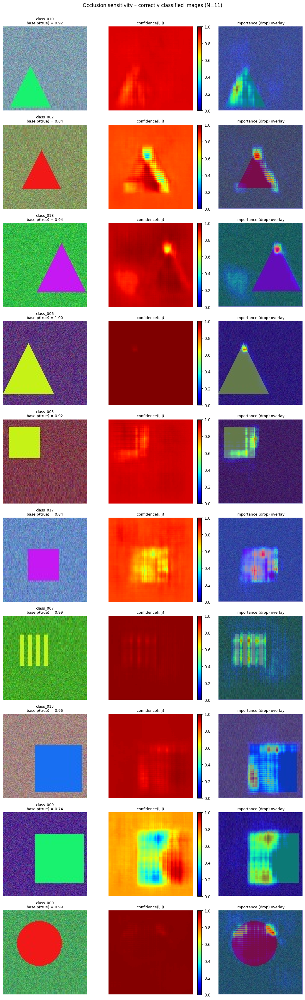

done in 9s


In [28]:
N_WIN, STRIDE = 11, 1
OCC = {}     # cache: image index -> (conf_map, pred_map, base)

def occlusion_report(indices, N=N_WIN, stride=STRIDE, title="", fname=None):
    rows, stats = len(indices), []
    fig, axes = plt.subplots(rows, 3, figsize=(11, 3.4 * rows))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(indices):
        t = int(yte[i]); H, W = Xte.shape[2:]
        key = (i, N, stride)
        if key not in OCC: OCC[key] = occlusion_map(best_model, Xte[i], t, N=N, stride=stride)
        cmap_, pmap_, base = OCC[key]
        img = to_numpy_img(Xte[i])
        axes[r, 0].imshow(img); axes[r, 0].set_title(f"{class_names[t]}\nbase p(true) = {base:.2f}", fontsize=9)
        im = axes[r, 1].imshow(cmap_, vmin=0, vmax=1, cmap="jet", extent=(0, W, H, 0)); axes[r, 1].set_title("confidence(i, j)", fontsize=9)
        plt.colorbar(im, ax=axes[r, 1], fraction=0.046)
        drop = np.clip(base - cmap_, 0, None); drop = drop / (drop.max() + 1e-8)
        axes[r, 2].imshow(img); axes[r, 2].imshow(drop, cmap="jet", alpha=0.5, extent=(0, W, H, 0)); axes[r, 2].set_title("importance (drop) overlay", fontsize=9)
        for a in axes[r]: a.axis("off")
        # numbers for the report
        iy, ix = np.unravel_index(cmap_.argmin(), cmap_.shape)
        stats.append(dict(img_index=i, true_class=class_names[t], base_conf=round(base, 3), min_conf=round(float(cmap_.min()), 3),
                          mean_conf=round(float(cmap_.mean()), 3),
                          area_conf_below_half_base_pct=round(float((cmap_ < 0.5 * base).mean() * 100), 1),
                          area_pred_changed_pct=round(float((pmap_ != t).mean() * 100), 1),
                          most_sensitive_xy=(int(ix * stride), int(iy * stride)),
                          dist_from_center_px=round(float(np.hypot(ix * stride - W / 2, iy * stride - H / 2)), 1)))
    plt.suptitle(title, y=1.0); plt.tight_layout()
    if fname: savefig(fname)
    plt.show()
    return pd.DataFrame(stats)

t0 = time.time()
stats_correct = occlusion_report(SEL_IDX, title=f"Occlusion sensitivity – correctly classified images (N={N_WIN})", fname="fig_occlusion_correct")
print(f"done in {time.time()-t0:.0f}s")

In [29]:
display(stats_correct)
stats_correct.to_csv(f"{OUT_DIR}/partB_occlusion_stats_correct.csv", index=False)
print("Average over the 10 images:")
print(stats_correct[["base_conf", "min_conf", "area_conf_below_half_base_pct", "area_pred_changed_pct", "dist_from_center_px"]].mean().round(2).to_string())

,img_index,true_class,base_conf,min_conf,mean_conf,area_conf_below_half_base_pct,area_pred_changed_pct,most_sensitive_xy,dist_from_center_px
0,35,class_010,0.918,0.776,0.912,0.0,0.0,"(18, 63)",31.9
1,78,class_002,0.837,0.295,0.826,0.2,0.2,"(38, 32)",10.8
2,76,class_018,0.945,0.597,0.943,0.0,0.0,"(58, 27)",21.9
3,64,class_006,1.000,0.972,0.999,0.0,0.0,"(25, 28)",22.0
4,56,class_005,0.923,0.749,0.923,0.0,0.0,"(35, 19)",24.0
5,108,class_017,0.838,0.532,0.829,0.0,0.0,"(43, 36)",6.1
6,106,class_007,0.987,0.932,0.984,0.0,0.0,"(29, 25)",21.4
7,11,class_013,0.957,0.890,0.952,0.0,0.0,"(34, 64)",23.4
8,0,class_009,0.740,0.210,0.690,2.8,10.2,"(49, 26)",17.5
9,20,class_000,0.993,0.957,0.991,0.0,0.0,"(54, 22)",23.3


Average over the 10 images:
base_conf                         0.91
min_conf                          0.69
area_conf_below_half_base_pct     0.30
area_pred_changed_pct             1.04
dist_from_center_px              20.23


### 7.3 Mis-classified images (for comparison)
Where does the model look when it is wrong? Here `confidence` is still the probability of the **true** class, so we can see which regions would have to be visible for the model to recognise the right object.

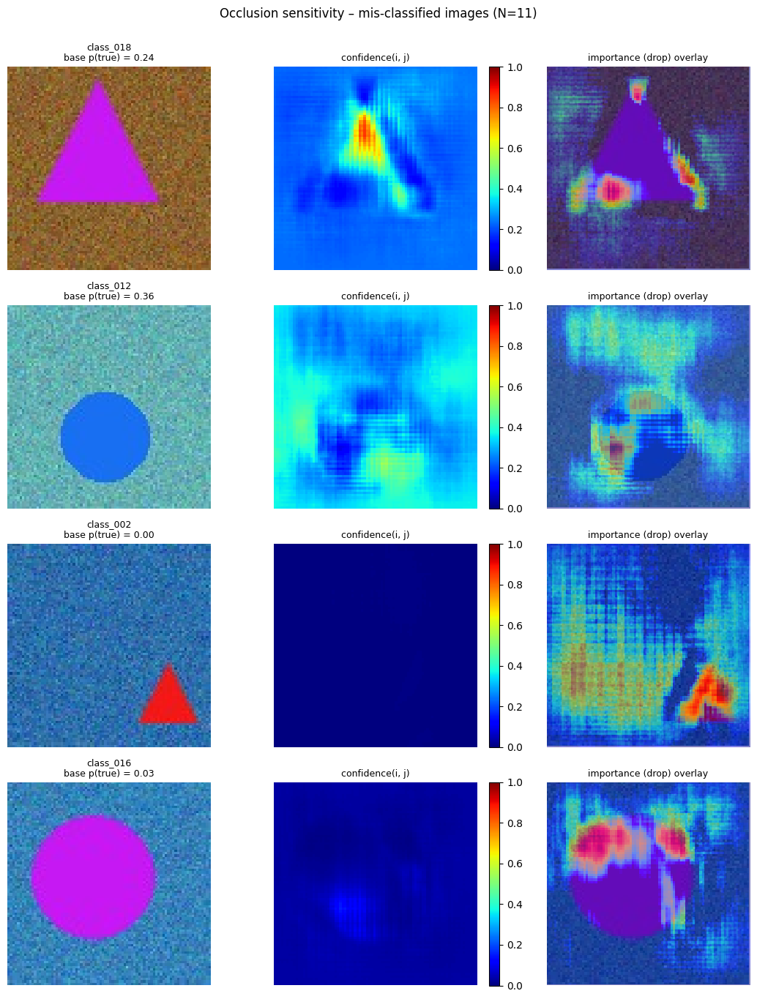

,img_index,true_class,base_conf,min_conf,mean_conf,area_conf_below_half_base_pct,area_pred_changed_pct,most_sensitive_xy,dist_from_center_px
0,73,class_018,0.237,0.111,0.252,0.1,96.7,"(25, 51)",19.2
1,50,class_012,0.362,0.092,0.316,2.1,90.2,"(27, 58)",21.9
2,82,class_002,0.004,0.001,0.003,12.1,100.0,"(72, 62)",36.1
3,37,class_016,0.031,0.006,0.032,6.6,100.0,"(15, 26)",31.4


In [30]:
stats_wrong = occlusion_report(SEL_WRONG, title=f"Occlusion sensitivity – mis-classified images (N={N_WIN})", fname="fig_occlusion_wrong")
display(stats_wrong)
stats_wrong.to_csv(f"{OUT_DIR}/partB_occlusion_stats_wrong.csv", index=False)

**How to interpret the maps (for the comments in your report)**
* **Compact dark/blue blob on the object** → the model has learnt the object's location/appearance; hiding the object kills the prediction while hiding the background does little.
* **Confidence stays high almost everywhere** (flat, bright map) → the decision is distributed or driven by **context/texture** (background, scene) – occluding any small window does not matter.
* **Drops located on the background** (e.g. water for a boat, grass for an animal) → context dependence.
* **Prediction flips** (`area_pred_changed_pct`) show whether occluding the object makes the model switch to a specific other class (often a context-compatible one).
* **Confidence can *increase*** when a distracting region is hidden (values above the base confidence) – this means that region was *supporting a competing class*.
* If the sensitive region of different images is always near the image centre (`dist_from_center_px` small), part of the behaviour may be a **centre bias** of the dataset (objects tend to be centred) rather than true localisation – see the dataset-level average in 7.5.

### 7.4 Effect of the window size N
Small windows hide only fine details (the model is robust), large windows hide whole objects. We compare N = 5, 11, 21, 31 on 3 of the selected images (every 2nd pixel for speed).

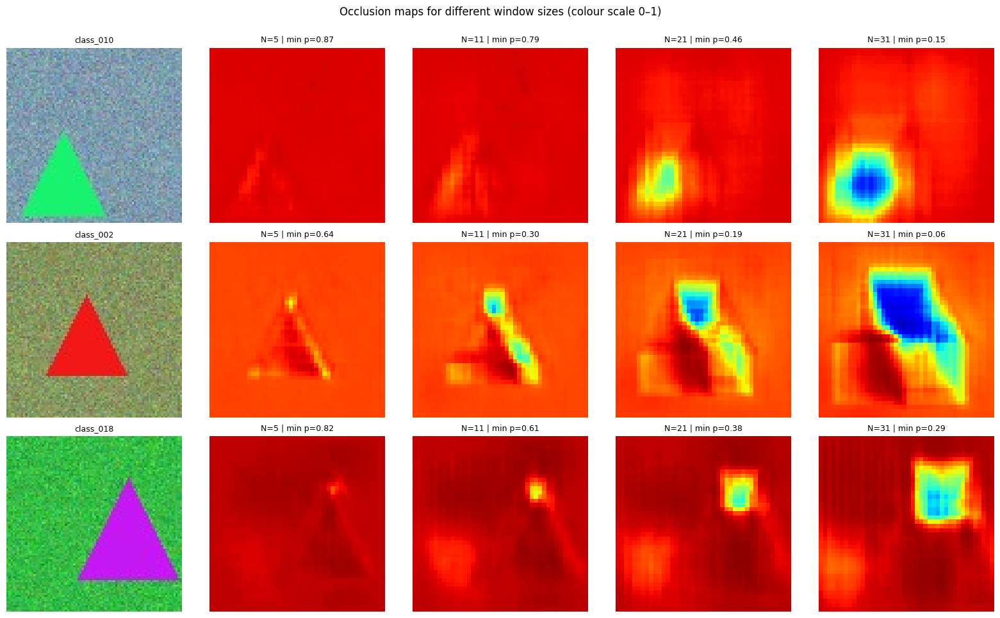

In [31]:
Ns, imgs = [5, 11, 21, 31], SEL_IDX[:3]
fig, axes = plt.subplots(len(imgs), len(Ns) + 1, figsize=(3.2 * (len(Ns) + 1), 3.2 * len(imgs)))
for r, i in enumerate(imgs):
    t = int(yte[i]); H, W = Xte.shape[2:]
    axes[r, 0].imshow(to_numpy_img(Xte[i])); axes[r, 0].set_title(class_names[t], fontsize=9); axes[r, 0].axis("off")
    for c, N in enumerate(Ns, start=1):
        cm_, _, base = occlusion_map(best_model, Xte[i], t, N=N, stride=2)
        im = axes[r, c].imshow(cm_, vmin=0, vmax=1, cmap="jet", extent=(0, W, H, 0))
        axes[r, c].set_title(f"N={N} | min p={cm_.min():.2f}", fontsize=9); axes[r, c].axis("off")
plt.suptitle("Occlusion maps for different window sizes (colour scale 0–1)", y=1.0)
plt.tight_layout(); savefig("fig_occlusion_window_sizes"); plt.show()

### 7.5 (Extra) Dataset-level view: average sensitivity over many test images
To check for a **systematic centre bias**, we average the *relative* confidence `confidence(i, j) / base confidence` over up to 300 correctly classified test images (window 11, stride 4). If the average map is dark in the centre and bright at the borders, the model relies mostly on the central region (where the objects typically are); a nearly uniform map would indicate that no particular location dominates.

occlusion (avg map):   0%|          | 0/104 [00:00<?, ?it/s]

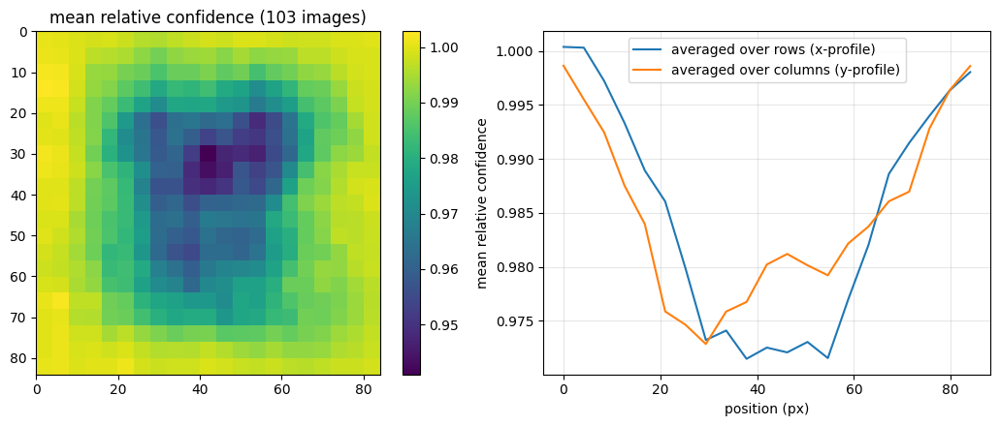

centre (middle 1/3 of image) mean relative conf: 0.958 | border region mean: 0.997


In [32]:
rng = np.random.RandomState(0)
pool_idx = rng.choice(correct_idx, min(300, len(correct_idx)), replace=False)
acc_map, n_used = None, 0
for i in tqdm(pool_idx, desc="occlusion (avg map)"):
    cm_, _, base = occlusion_map(best_model, Xte[int(i)], int(yte[int(i)]), N=11, stride=4)
    if base < 0.2: continue
    rel = cm_ / base
    acc_map = rel if acc_map is None else acc_map + rel; n_used += 1
avg_map = acc_map / n_used
H, W = Xte.shape[2:]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
im = ax[0].imshow(avg_map, cmap="viridis", extent=(0, W, H, 0)); ax[0].set_title(f"mean relative confidence ({n_used} images)")
plt.colorbar(im, ax=ax[0], fraction=0.046)
ax[1].plot(np.linspace(0, W, avg_map.shape[1]), avg_map.mean(0), label="averaged over rows (x-profile)")
ax[1].plot(np.linspace(0, H, avg_map.shape[0]), avg_map.mean(1), label="averaged over columns (y-profile)")
ax[1].set_xlabel("position (px)"); ax[1].set_ylabel("mean relative confidence"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); savefig("fig_occlusion_average_map"); plt.show()
print(f"centre (middle 1/3 of image) mean relative conf: {avg_map[avg_map.shape[0]//3: 2*avg_map.shape[0]//3, avg_map.shape[1]//3: 2*avg_map.shape[1]//3].mean():.3f}"
      f" | border region mean: {np.mean(np.concatenate([avg_map[:3].ravel(), avg_map[-3:].ravel(), avg_map[:, :3].ravel(), avg_map[:, -3:].ravel()])):.3f}")

## Step 8 – Save everything for the report
Saves the best model, the full results table and all figures (already written to `/content/outputs`) and optionally copies them to Google Drive.

In [33]:
torch.save(dict(cfg=BEST["cfg"], state_dict=BEST["state"], classes=classes, class_names=class_names,
                mean=MEAN.cpu(), std=STD.cpu(), name=BEST["name"]), f"{OUT_DIR}/best_model.pt")
res = pd.DataFrame(RESULTS)
res.to_csv(f"{OUT_DIR}/partA_results_table_all_runs.csv", index=False)
res.to_markdown(f"{OUT_DIR}/partA_results_table_all_runs.md", index=False)

summary = dict(best_model=BEST["name"], config={k: str(v) for k, v in BEST["cfg"].items()},
               val_acc=round(BEST["val_acc"] * 100, 2), test_acc_top1=round(t1 * 100, 2), test_acc_top5=round(t5 * 100, 2),
               params_M=round(count_params(best_model), 2), occlusion_window=N_WIN)
json.dump(summary, open(f"{OUT_DIR}/best_model_summary.json", "w"), indent=2)
print(json.dumps(summary, indent=2)); print("\nFiles in", OUT_DIR, ":"); print(*sorted(os.listdir(OUT_DIR)), sep="\n  ")

SAVE_TO_DRIVE = True
if SAVE_TO_DRIVE and os.path.isdir("/content/drive/MyDrive"):
    dst = "/content/drive/MyDrive/dl_assignment_outputs"
    shutil.copytree(OUT_DIR, dst, dirs_exist_ok=True); print("\nCopied to", dst)

{
  "best_model": "epochs: 30 epochs, constant LR (final / best-val)",
  "config": {
    "conv_channels": "(32, 64, 128)",
    "convs_per_block": "1",
    "kernel_size": "3",
    "stride": "1",
    "stride_mode": "first",
    "use_pool": "True",
    "fc_sizes": "(256,)",
    "dropout": "0.3",
    "use_bn": "True",
    "num_classes": "20"
  },
  "val_acc": 78.51,
  "test_acc_top1": 86.67,
  "test_acc_top5": 99.17,
  "params_M": 0.62,
  "occlusion_window": 11
}

Files in /content/outputs :
best_model.pt
  best_model_summary.json
  fig_confused_pairs_examples.png
  fig_epochs_curve.png
  fig_improved_curves.png
  fig_misclassified_confident.png
  fig_misclassified_random.png
  fig_occlusion_average_map.png
  fig_occlusion_correct.png
  fig_occlusion_window_sizes.png
  fig_occlusion_wrong.png
  fig_partA_ablation_bars.png
  fig_per_class_accuracy.png
  fig_samples.png
  partA_results_table_all_runs.csv
  partA_results_table_all_runs.md
  partA_top_confusions.csv
  partB_occlusion_stats_cor

---
### ✅ Coding part complete – what you now have
| Deliverable | File |
|---|---|
| Part A results table (all runs, one factor at a time + improved models) | `partA_results_table_all_runs.csv / .md` |
| Ablation bar charts, learning curves | `fig_partA_ablation_bars.png`, `fig_epochs_curve.png`, `fig_improved_curves.png` |
| Mis-classification analysis | `fig_misclassified_*.png`, `fig_per_class_accuracy.png`, `fig_confused_pairs_examples.png`, `partA_top_confusions.csv` |
| Part B occlusion maps + statistics | `fig_occlusion_*.png`, `partB_occlusion_stats_*.csv` |
| Best model | `best_model.pt`, `best_model_summary.json` |

When you are ready, share the numbers/figures and I will help you write the summary report (remember: no code screenshots in the report, submit the `.ipynb` along with it).